<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">05 · Segmentation & targeting score</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Which doctors to prioritise for the 2026 GLP-1 opportunity, and the evidence behind each choice</p>

| | |
|---|---|
| **Goal** | Rank 308k doctors for the Medicare GLP-1 Bridge (Jul 2026) + oral Foundayo launch, with a reason for every rank |
| **Code** | `src/glp1_intel/models/targeting.py` · `src/glp1_intel/data_processing/kol_links.py` |
| **Output** | `data/03_processed/targeting_scores.parquet` (score, rank, segment, reasons per doctor) |
| **Skills** | Entity resolution · segmentation (rules vs k-means) · scoring · explainability · sensitivity analysis |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Segmentation vs targeting</b>

Pharma sales optimisation answers three questions:

| Question | Technique | Here |
|---|---|---|
| **Who are our customers?** | **Segmentation**: group doctors who behave alike | 6 business segments (+ k-means check) |
| **Who matters most right now?** | **Targeting**: rank doctors for a specific objective | 0–100 score for the 2026 opportunity |
| **Why them?** | **Explainability**: evidence a rep and an analyst can trust | 3 plain-language reasons per doctor |

The classic frame is **potential × adoption**: how many relevant patients a doctor has (potential) vs how much of that they already treat with our class of drug (adoption).

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from glp1_intel import viz
from glp1_intel.viz import SEGMENT_COLOR, MUTED, TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.data_processing import kol_links
from glp1_intel.models import targeting
from glp1_intel.paths import PROCESSED

hcp = pd.read_parquet(PROCESSED / "hcp_360.parquet")
print(f"HCP 360: {len(hcp):,} doctors")

HCP 360: 316,559 doctors


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · Research signals: linking authors and investigators to doctors

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Entity resolution without a shared ID</b>

PubMed authors and trial investigators have **no NPI**, only names and addresses. Matching them to doctors is **entity resolution**.

- **Key:** `(LAST NAME, FIRST INITIAL, STATE)`, with names normalised (upper-case, accents and hyphens removed: *García-López → GARCIALOPEZ*).
- **State** is parsed from the affiliation ("…, Houston, TX 77030, USA" → TX).
- **Keep only unique matches.** If two doctors share the key, we don't guess.

This is **precision over recall**: missing a researcher costs little, but attaching the wrong doctor's papers to a pre-visit brief would destroy trust.

</div>

In [2]:
pub    = kol_links.pubmed_links(hcp)          # one row per (paper, US author)
trials = kol_links.trial_links(hcp)           # one row per (study, US investigator)
kol    = kol_links.npi_features(pub, trials)  # per-NPI counts of papers and trials

show(pd.concat([kol_links.match_summary(pub, "PubMed authors (US)"),
                kol_links.match_summary(trials, "Trial investigators (US)")]),
     "Match quality: every name ends in exactly one bucket")
print(f"Doctors with at least one research signal: {len(kol):,}")

Doctors with at least one research signal: 1,197


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Matched** = exactly one doctor has that key. **Ambiguous** = several doctors share it (common names), so it's left unlinked. **Not found** = mostly PhD scientists, non-US-practising authors or doctors outside Medicare Part D: expected, not an error.
- The result is a small but valuable group of **~1,200 research-active prescribers** (KOL candidates), which becomes the `research` component below.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out</b>

A unique key can still be wrong (two "J. Smith"s in Texas, one in HCP 360 and one not). With more time we'd add **city** and **specialty** to the key and **hand-check a random sample** to estimate precision; that's listed for the evaluation report.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Segmentation: six business segments

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Rule-based segmentation</b>

| Segment | Rule (first match wins) | Commercial play |
|---|---|---|
| **A · Tirzepatide champions** | top-30% GLP-1 volume, tirzepatide ≥ 50% vs semaglutide | maintain, and introduce Foundayo first |
| **B · High-value swing** | top-30% GLP-1 volume, uses both molecules | highest-value conversations |
| **C · Competitor strongholds** | top-30% GLP-1 volume, semaglutide ≥ 80% | evidence-led, long-term |
| **D · Untapped potential** | top-30% diabetes volume, GLP-1 < 10% of diabetes Rx | education, expansion |
| **E · Developing GLP-1 users** | mid-volume GLP-1 prescribers | efficient channels (digital, inside sales) |
| **F · Low volume** | everyone else | non-personal promotion only |

**Why rules rather than only an algorithm?** Rules are **explainable** ("why is Dr X in segment D?"), **stable** over time and **aligned** with how sales teams plan. We'll still run k-means in section 5 as a data-driven cross-check.

</div>

In [3]:
scores = targeting.build(hcp, kol)                        # score + rank + segment + reasons, saved to parquet

seg = (scores.groupby("segment")
             .agg(doctors=("npi", "size"),
                  diabetes_claims=("diabetes_total_claims", "sum"),
                  glp1_claims=("glp1_claims", "sum"),
                  avg_score=("score", "mean"))
             .reset_index())
seg["pct_doctors"]  = 100 * seg["doctors"] / seg["doctors"].sum()
seg["pct_diabetes"] = 100 * seg["diabetes_claims"] / seg["diabetes_claims"].sum()
show(seg, f"Segments ({len(scores):,} eligible doctors; deactivated NPIs and trainees excluded)")

segment,doctors,diabetes_claims,glp1_claims,avg_score,pct_doctors,pct_diabetes
A · Tirzepatide champions,"10,982","9,282,836","2,657,671",70.3,3.6,9.0
B · High-value swing,"28,618","28,511,569","7,175,002",74.1,9.3,27.6
C · Competitor strongholds,"19,950","19,881,779","3,956,933",65.0,6.5,19.3
D · Untapped potential,"20,181","14,325,298","605,838",55.5,6.5,13.9
E · Developing GLP-1 users,"69,730","19,143,928","4,142,586",52.1,22.6,18.5
F · Low volume,"158,842","12,109,343","917,636",33.9,51.5,11.7


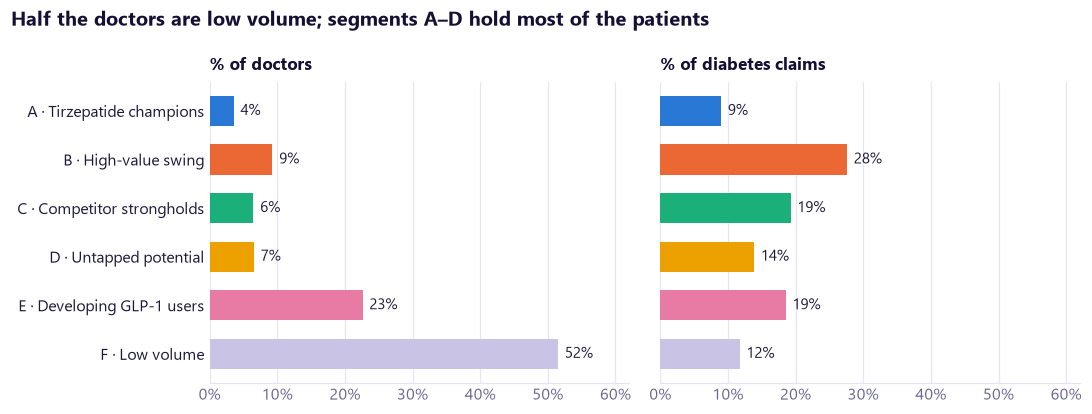

In [4]:
# ── Two small panels (never one chart with two y-axes) ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
order = seg.sort_values("segment", ascending=False)
colors = [SEGMENT_COLOR[s[0]] for s in order["segment"]]
for ax, col, title in [(axes[0], "pct_doctors", "% of doctors"), (axes[1], "pct_diabetes", "% of diabetes claims")]:
    ax.barh(order["segment"], order[col], color=colors, height=0.62)
    for y, v in enumerate(order[col]):
        ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9.5, color=TEXT)
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlim(0, 62)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.suptitle("Half the doctors are low volume; segments A–D hold most of the patients", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "05_1_segments")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **F · Low volume** is about half of all doctors but only a small share of diabetes claims. Visiting them in person would waste rep time.
- **B · High-value swing** (~9% of doctors) holds the largest share of diabetes claims: the core of any 2026 plan.
- **D · Untapped potential** (~7% of doctors) has a large diabetes base but almost no GLP-1 use: an **expansion** audience, not a quick win.

</div>

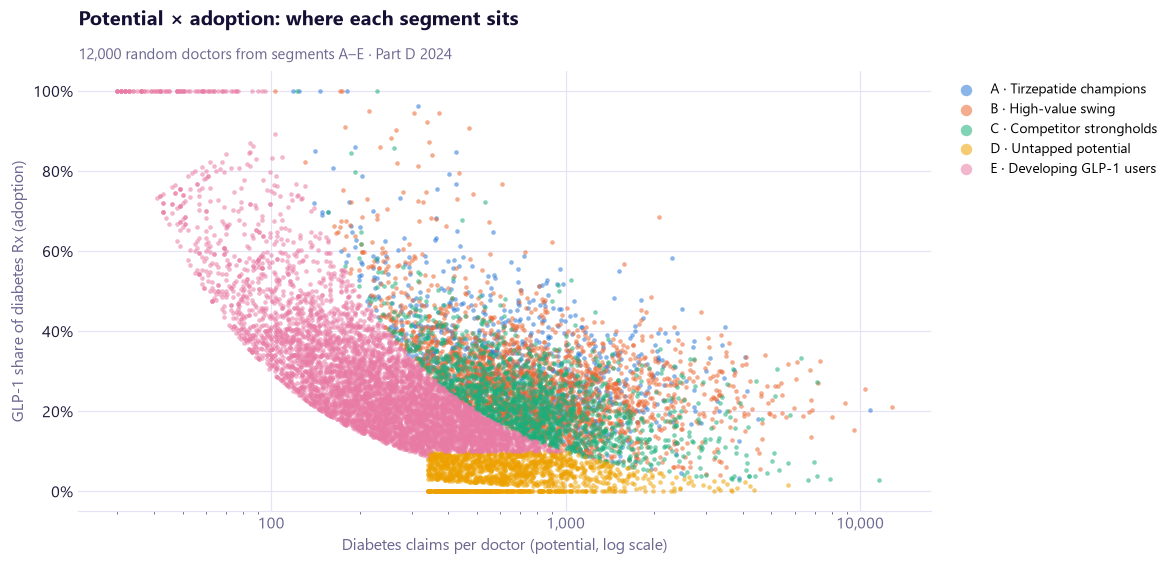

In [5]:
# ── Potential × adoption map (random sample for legibility) ─────────────────
sample = scores[scores["segment"].str[0] != "F"].sample(12000, random_state=1)
fig, ax = plt.subplots(figsize=(10, 5.2))
for s in sorted(sample["segment"].unique()):
    d = sample[sample["segment"] == s]
    ax.scatter(d["diabetes_total_claims"], 100 * d["glp1_share_of_diabetes"].fillna(0),
               s=9, alpha=0.55, color=SEGMENT_COLOR[s[0]], label=s, linewidths=0)
ax.set_xscale("log")
ax.set_xlabel("Diabetes claims per doctor (potential, log scale)")
ax.set_ylabel("GLP-1 share of diabetes Rx (adoption)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=2.5, fontsize=9)
ax.set_title("Potential × adoption: where each segment sits")
subtitle(ax, "12,000 random doctors from segments A–E · Part D 2024")
viz.save(fig, "05_2_potential_vs_adoption")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The x-axis is **potential** (patient base) and the y-axis is **adoption** (GLP-1 share).
- **D · Untapped** (yellow) sits **bottom-right**: big diabetes practices, low GLP-1 use.
- **A/B/C** (blue/orange/green) sit to the right at **20–50% adoption**: the established, high-volume GLP-1 prescribers. They overlap here because they differ on a **third** dimension this chart doesn't show (tirzepatide vs semaglutide loyalty).
- **E · Developing** (pink) forms the curved band on the left: smaller practices where a few GLP-1 claims already make a high share.
- The **log scale** is necessary because practice sizes span 1,000× (from ~10 to ~10,000 claims).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · The targeting score

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · A transparent, weighted scoring model</b>

There's **no label to learn from**: nobody has observed 2026 doctor-level prescribing yet. So instead of training a black-box model, we write the commercial logic as **explicit components**, each scaled 0–1:

| Component | Weight | Logic |
|---|---|---|
| `potential` | 30% | percentile of diabetes claims: more patients who could benefit |
| `glp1_experience` | 20% | percentile of GLP-1 claims: comfortable with the class, so likely early with the Bridge |
| `headroom` | 15% | 1 − GLP-1 share of diabetes Rx: room to grow |
| `tirzepatide_openness` | 15% | uses both molecules = 1.0 · tirzepatide-loyal = 0.6 · semaglutide-loyal = 0.3 |
| `oral_affinity` | 10% | prescribes oral semaglutide (Rybelsus), the natural audience for **oral** Foundayo |
| `research` | 5% | linked papers / trials (KOL signal) |
| `coverage_gap` | 5% | no Lilly payment of any kind recorded in Open Payments 2024–2025 |

`score = 100 × Σ weight × component`. **Percentile ranks** make components comparable and robust to extreme values (one doctor with 10,000 claims doesn't distort everyone else).
Each doctor's **3 largest weighted contributions** become their plain-language **reasons**.

</div>

In [6]:
top_view = scores.head(10)[["rank", "specialty", "city", "state", "segment", "score", "reasons"]]
show(top_view, "Top 10 doctors for the 2026 opportunity (names hidden)")

rank,specialty,city,state,segment,score,reasons
1,Physician Assistant,Springfield,MO,B · High-value swing,92.9,"large diabetes patient base (6,920 diabetes claims, top 1%) · experienced GLP-1 prescriber (857 GLP-1 claims) · already uses both tirzepatide and semaglutide"
2,Internal Medicine,Brooklyn,NY,B · High-value swing,92.4,"large diabetes patient base (3,943 diabetes claims, top 1%) · experienced GLP-1 prescriber (397 GLP-1 claims) · already uses both tirzepatide and semaglutide"
3,Endocrinology,Buffalo,NY,B · High-value swing,92.3,"large diabetes patient base (3,524 diabetes claims, top 1%) · experienced GLP-1 prescriber (1,048 GLP-1 claims) · already uses both tirzepatide and semaglutide"
4,Endocrinology,Rockford,IL,B · High-value swing,92.3,"large diabetes patient base (4,372 diabetes claims, top 1%) · experienced GLP-1 prescriber (632 GLP-1 claims) · already uses both tirzepatide and semaglutide"
5,Endocrinology,Glendale,CA,B · High-value swing,92.3,"large diabetes patient base (10,398 diabetes claims, top 1%) · experienced GLP-1 prescriber (1,853 GLP-1 claims) · already uses both tirzepatide and semaglutide"
6,Endocrinology,Huntsville,AL,A · Tirzepatide champions,92.2,"large diabetes patient base (5,628 diabetes claims, top 1%) · experienced GLP-1 prescriber (666 GLP-1 claims) · already uses both tirzepatide and semaglutide"
7,Emergency Medicine,Bell,CA,B · High-value swing,92.2,"large diabetes patient base (4,593 diabetes claims, top 1%) · experienced GLP-1 prescriber (565 GLP-1 claims) · already uses both tirzepatide and semaglutide"
8,Endocrinology,Indianapolis,IN,B · High-value swing,92.2,"large diabetes patient base (4,035 diabetes claims, top 1%) · experienced GLP-1 prescriber (580 GLP-1 claims) · already uses both tirzepatide and semaglutide"
9,Endocrinology,Jefferson City,MO,B · High-value swing,92.2,"large diabetes patient base (7,944 diabetes claims, top 1%) · experienced GLP-1 prescriber (1,391 GLP-1 claims) · already uses both tirzepatide and semaglutide"
10,Internal Medicine,Hayti,MO,B · High-value swing,92.1,"large diabetes patient base (4,158 diabetes claims, top 1%) · experienced GLP-1 prescriber (585 GLP-1 claims) · already uses both tirzepatide and semaglutide"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Every row says **why**: e.g. *"large diabetes patient base (top 1%) · experienced GLP-1 prescriber (1,201 GLP-1 claims) · already uses both tirzepatide and semaglutide"*.
That sentence is what a rep sees in the pre-visit brief and what the Ask-AI agent cites, so it's explainable by design.

</div>

In [7]:
top10k = scores.head(10_000)
mix = pd.DataFrame({
    "top 10,000":    top10k["specialty"].value_counts(normalize=True).head(6) * 100,
    "all doctors":   scores["specialty"].value_counts(normalize=True) * 100,
}).dropna().reset_index(names="specialty")
display(show(mix, "Who makes the top 10,000? Specialty mix (%)"))
show((top10k["segment"].value_counts(normalize=True) * 100).rename_axis("segment").reset_index(name="pct_of_top_10k"),
     "Segment mix of the top 10,000 (%)")

specialty,"top 10,000",all doctors
Endocrinology,20.1,2.0
Family Practice,29.2,26.5
General Practice,0.8,1.5
Internal Medicine,28.4,20.2
Nurse Practitioner,14.3,27.8
Physician Assistant,5.0,8.7


segment,pct_of_top_10k
B · High-value swing,80.0
A · Tirzepatide champions,15.7
C · Competitor strongholds,3.4
E · Developing GLP-1 users,0.6
D · Untapped potential,0.4


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Endocrinologists are ~2% of doctors but ~20% of the top 10,000**: the score finds high-intensity specialists without being told to.
- The top 10,000 are mostly **B · High-value swing** and **A · Champions**: doctors most likely to act **first** when 65+ patients gain coverage in July 2026.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Circular reasoning</b>

**Don't measure a gap with a score that rewards the gap.** The score gives +5 points to doctors with no Lilly payment, so "how many top-ranked doctors lack contact?"
would partly echo our own bonus (circular reasoning). We answer it with the score **re-computed without** the `coverage_gap` component.

</div>

In [8]:
comp_wo_gap = scores[[c for c in scores if c.startswith("c_") and c != "c_coverage_gap"]].rename(columns=lambda c: c[2:])
readiness = targeting.weighted_score(comp_wo_gap)            # Bridge readiness only, no coverage bonus

rows = []
for k in (1_000, 10_000):
    d = scores.loc[readiness.nlargest(k).index]
    rows.append({"group": f"top {k:,} by readiness",
                 "pct_no_lilly_payment":  100 * (d["op_lilly_payments"] == 0).mean(),
                 "pct_no_novo_payment":   100 * (d["op_novo_payments"] == 0).mean(),
                 "pct_novo_but_not_lilly": 100 * ((d["op_lilly_payments"] == 0) & (d["op_novo_payments"] > 0)).mean()})
rows.append({"group": "all eligible doctors",
             "pct_no_lilly_payment":  100 * (scores["op_lilly_payments"] == 0).mean(),
             "pct_no_novo_payment":   100 * (scores["op_novo_payments"] == 0).mean(),
             "pct_novo_but_not_lilly": 100 * ((scores["op_lilly_payments"] == 0) & (scores["op_novo_payments"] > 0)).mean()})
show(pd.DataFrame(rows), "Coverage gap: payment records 2024–2025 (%), ranked WITHOUT the coverage component")

group,pct_no_lilly_payment,pct_no_novo_payment,pct_novo_but_not_lilly
"top 1,000 by readiness",27.8,21.3,10.3
"top 10,000 by readiness",33.0,27.1,10.3
all eligible doctors,71.4,66.1,10.8


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **About one in three of the 10,000 most Bridge-ready doctors had no Lilly payment record** of any kind in 2024–2025 (not even a ~$20 meal during a visit).
- **~10% were engaged by Novo Nordisk but not by Lilly**: a **competitive coverage gap**, the most actionable "under-targeted" list for a sales-planning meeting.
- Across all doctors, ~71% have no Lilly record; most of them are low-volume, which is expected and fine.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out</b>

**One score can't serve every objective.** This score ranks *Bridge readiness*, so **D · Untapped potential** doctors rarely reach the top 10,000.
An **expansion** campaign should use its own list. Below: the top of segment D, sorted by the same score.

</div>

In [9]:
expansion = scores[scores["segment"].str.startswith("D")].head(8)[["rank", "specialty", "state", "diabetes_total_claims",
                                                                     "glp1_share_of_diabetes", "score", "reasons"]]
show(expansion, "Expansion list: top 'Untapped potential' doctors", precision=2)

rank,specialty,state,diabetes_total_claims,glp1_share_of_diabetes,score,reasons
"1,811",Family Practice,NC,"1,394",0.07,85.90,"large diabetes patient base (1,394 diabetes claims, top 4%) · already uses both tirzepatide and semaglutide · GLP-1s only 7% of diabetes Rx: room to grow"
"3,027",Internal Medicine,MI,"4,068",0.02,84.40,"large diabetes patient base (4,068 diabetes claims, top 1%) · already uses both tirzepatide and semaglutide · GLP-1s only 2% of diabetes Rx: room to grow"
"3,047",Family Practice,NY,"2,124",0.05,84.40,"large diabetes patient base (2,124 diabetes claims, top 2%) · already uses both tirzepatide and semaglutide · GLP-1s only 5% of diabetes Rx: room to grow"
"3,148",Family Practice,KY,"1,524",0.06,84.30,"large diabetes patient base (1,524 diabetes claims, top 3%) · already uses both tirzepatide and semaglutide · GLP-1s only 6% of diabetes Rx: room to grow"
"3,468",Family Practice,NY,"1,280",0.07,84.00,"large diabetes patient base (1,280 diabetes claims, top 5%) · already uses both tirzepatide and semaglutide · GLP-1s only 7% of diabetes Rx: room to grow"
"3,662",Internal Medicine,VA,"1,002",0.10,83.80,"large diabetes patient base (1,002 diabetes claims, top 7%) · already uses both tirzepatide and semaglutide · experienced GLP-1 prescriber (98 GLP-1 claims)"
"3,664",Internal Medicine,NV,"1,070",0.08,83.80,"large diabetes patient base (1,070 diabetes claims, top 7%) · already uses both tirzepatide and semaglutide · GLP-1s only 8% of diabetes Rx: room to grow"
"3,994",Internal Medicine,CT,"1,231",0.07,83.50,"large diabetes patient base (1,231 diabetes claims, top 5%) · already uses both tirzepatide and semaglutide · GLP-1s only 8% of diabetes Rx: room to grow"


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · How much do the chosen weights matter? Sensitivity analysis

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Robustness of a judgement-based model</b>

The weights are **judgement calls**, so we have to show the ranking doesn't hinge on them.
We re-score everyone **50 times**, each time multiplying every weight by a random factor between 0.8 and 1.2, and measure:
- **Top-10k overlap:** share of the original top-10,000 still in the new top-10,000
- **Spearman correlation:** agreement of the full ranking (1.0 = identical order)

</div>

In [10]:
comp = scores[[c for c in scores if c.startswith("c_")]].rename(columns=lambda c: c[2:])
sens = targeting.weight_sensitivity(comp, n=50, jitter=0.2, top_k=10_000)
show(sens.describe().loc[["mean", "min", "max"]].reset_index(names="statistic"), "Ranking stability under ±20% weight changes", precision=3)

statistic,top_k_overlap,spearman
mean,0.949,0.999
min,0.915,0.998
max,0.976,1.000


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- On average **~95% of the top-10,000 stays the same**, and even the worst of 50 trials keeps ~92%.
- **Spearman ≈ 0.999**: the overall order barely moves.
- So the **conclusions don't depend on the exact weights**. This is the evidence to show when someone asks *"why 30% and not 25%?"*

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Cross-check: what does k-means find on its own?

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · k-means, standardisation and silhouette</b>

**k-means** places *k* centres and assigns each doctor to the nearest one, moving the centres until they settle: unsupervised, no business rules.

1. **Standardise** features (mean 0, sd 1), otherwise claims in the thousands would swamp shares between 0 and 1.
2. **Log-transform** counts: claims are heavily skewed.
3. **Choose k** with the **silhouette score** (−1…1; how much closer each point is to its own cluster than to the next one).
4. **Compare** with our rules using the **Adjusted Rand Index** (ARI: 0 = random agreement, 1 = identical).

</div>

In [11]:
X = pd.DataFrame({
    "log_diabetes_claims": np.log1p(scores["diabetes_total_claims"]),
    "glp1_share":          scores["glp1_share_of_diabetes"].fillna(0),
    "tirzepatide_share":   scores["tirzepatide_share"].fillna(scores["tirzepatide_share"].median()),
    "log_glp1_claims":     np.log1p(scores["glp1_claims"]),
    "oral_glp1":           (scores["rybelsus_claims"] > 0).astype(float),
})
Z = StandardScaler().fit_transform(X)

# ── Choose k on a 20k sample (silhouette is O(n²)) ──────────────────────────
idx = np.random.default_rng(0).choice(len(Z), 20_000, replace=False)
sil = pd.DataFrame([{"k": k, "silhouette": silhouette_score(Z[idx], KMeans(k, n_init=5, random_state=0).fit_predict(Z[idx]))}
                    for k in range(3, 9)])
show(sil, "Silhouette by number of clusters (higher = better separated)", precision=3)

k,silhouette
3,0.454
4,0.483
5,0.502
6,0.494
7,0.466
8,0.454


In [12]:
best_k = int(sil.loc[sil["silhouette"].idxmax(), "k"])
km = KMeans(best_k, n_init=10, random_state=0).fit(Z)
scores["cluster"] = km.labels_

profile = X.assign(cluster=km.labels_).groupby("cluster").agg(
    doctors=("glp1_share", "size"),
    median_diabetes_claims=("log_diabetes_claims", lambda s: np.expm1(s.median())),
    glp1_share=("glp1_share", "mean"),
    tirzepatide_share=("tirzepatide_share", "mean"),
    pct_oral=("oral_glp1", "mean"),
).reset_index()
display(show(profile, f"k-means profile (k = {best_k})", precision=2))

ari = adjusted_rand_score(scores["segment"], scores["cluster"])
print(f"Adjusted Rand Index, rules vs k-means: {ari:.2f}")
show(pd.crosstab(scores["segment"], scores["cluster"]).reset_index(), "Which clusters do our segments fall into? (counts)")

cluster,doctors,median_diabetes_claims,glp1_share,tirzepatide_share,pct_oral
0,"99,695",262.00,0.19,0.06,0.00
1,"111,313",38.00,0.00,0.14,0.00
2,"34,963",632.00,0.25,0.22,1.00
3,"14,298",28.00,0.82,0.27,0.01
4,"48,034",329.00,0.28,0.58,0.00


Adjusted Rand Index, rules vs k-means: 0.33


segment,0,1,2,3,4
A · Tirzepatide champions,0,0,"2,542",193,"8,247"
B · High-value swing,"5,375",0,"11,685",525,"11,033"
C · Competitor strongholds,"11,510",0,"8,287",153,0
D · Untapped potential,"12,530","4,300","1,645",0,"1,706"
E · Developing GLP-1 users,"36,016",0,"8,987","4,066","20,661"
F · Low volume,"34,264","107,013","1,817","9,361","6,387"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

k = 5 has the best silhouette (0.50). Reading the profile table, the five clusters are:
- **Non-adopters** (~111k): small diabetes practices, no GLP-1s.
- **Semaglutide-leaning** (~100k): mid-size, GLP-1 ≈ 20% of diabetes Rx, tirzepatide only ~6%.
- **Tirzepatide-leaning** (~48k): tirzepatide ≈ 58% vs semaglutide.
- **Oral-GLP-1 prescribers** (~35k): *all* prescribe Rybelsus, with the **largest practices** (median ~630 diabetes claims). The natural **Foundayo** launch audience.
- **GLP-1-focused small practices** (~14k): few diabetes claims but GLP-1s ≈ 82% of them, possibly weight-management clinics.

**ARI = 0.33**: partial agreement. k-means confirms our main axes (volume, adoption, loyalty) but cuts along one more: **oral GLP-1 use**, which our rules only used inside the score. That's a concrete recommendation: add an **"oral-ready"** flag to the segments for the Foundayo launch.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Rules vs clustering</b>

**Use rules for the product, algorithms for discovery.** Rules give stable, explainable segments a sales team can act on; k-means checks they reflect real structure and surfaces patterns we might miss (here: 35k oral-GLP-1 prescribers and 14k GLP-1-focused clinics).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **No ground truth yet:** the score encodes commercial logic, not learned outcomes. When 2026 prescribing is published, back-test it (did high scorers adopt Foundayo first?) and learn the weights.
2. **Medicare 2024 behaviour** stands in for 2026 behaviour; commercial-insurance patients are invisible.
3. **Name-based links** (papers, trials) are precision-first but unverified; a hand-checked sample belongs in the evaluation report.
4. **Coverage gap** uses payments as a proxy for contact. Many rep visits involve no payment, so "no payment" ≠ "never visited".
5. Targeting decides **who receives relevant information first**, never what a doctor should prescribe.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** 308,303 eligible doctors scored, ranked, segmented and explained → `data/03_processed/targeting_scores.parquet`.
**Next:** the **analyst dashboard** (Streamlit, Aurora theme) showing market, segments and the ranked list, then NLP (notebooks 06–08).

**Check your understanding**
- *How do you target doctors without labels?* A transparent weighted score of business components, percentile-scaled, with reasons and a sensitivity test.
- *Why percentile ranks?* Comparable 0–1 scales that are robust to extreme prescribers.
- *How do you know the weights don't drive the answer?* ±20% random perturbation keeps ~95% of the top 10,000.
- *Rules or clustering for segmentation?* Rules for explainable, stable action; k-means (standardised, silhouette-chosen k, ARI vs rules) for validation and discovery.
- *How did you link PubMed authors to doctors?* Normalised (last name, initial, state) keys, unique matches only, with match-quality reporting.
- *Why separate expansion and Bridge-readiness lists?* Different objectives need different rankings; one score can't serve both.

</div>